# Progetto finale Python - ToysGroup

## Analisi delle vendite e dei rivenditori

In questo progetto lavoro sui dati di ToysGroup, un'azienda che vende giocattoli tramite diversi rivenditori. Prima controllo i file e sistemo i dati mancanti, poi analizzo le vendite con tabelle e grafici. Alla fine provo anche due tecniche di Machine Learning: una per capire quali rivenditori potrebbero smettere di acquistare e una per dividerli in gruppi.

Ho organizzato il lavoro seguendo i task della traccia, in modo da vedere il codice e il risultato di ogni passaggio.


## Preparazione dei file

Per eseguire il notebook servono i quattro file della cartella `dati`. Se uso Google Colab, devo caricare anche quella cartella (oppure lo ZIP ed estrarlo), non solo il notebook. Qui importo le librerie che mi serviranno nel progetto.


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

BASE = Path.cwd()
DATI = BASE / "dati"
PRODOTTI_FILE = DATI / "ESERCIZIO_M4-4-2_traccia_finale-products.csv"
REGIONI_FILE = DATI / "ESERCIZIO_M4-4-2_traccia_finale-regions.xlsx"
RIVENDITORI_FILE = DATI / "ESERCIZIO_M4-4-2_traccia_finale-resellers.csv"
VENDITE_FILE = DATI / "ESERCIZIO_M4-4-2_traccia_finale-sales.json"

for file in [PRODOTTI_FILE, REGIONI_FILE, RIVENDITORI_FILE, VENDITE_FILE]:
    assert file.exists(), f"File non trovato: {file}"

sns.set_theme(style="whitegrid")
print("Tutti e quattro i file sono presenti.")

Tutti e quattro i file sono presenti.


---
## Task 1 - Prime operazioni con Python

Inizio leggendo i dati e facendo alcuni calcoli usando soprattutto liste, dizionari, cicli e condizioni. In questo task uso Pandas solo per leggere i file, come richiesto dalla traccia.


In [2]:
# Leggo i file e preparo liste e dizionari
prodotti_lista = pd.read_csv(PRODOTTI_FILE).to_dict(orient="records")
with open(VENDITE_FILE, "r", encoding="utf-8") as file:
    vendite_lista = json.load(file)
regioni_lista = pd.read_excel(REGIONI_FILE).to_dict(orient="records")

regioni_dict = {r["RegionID"]: (r["State"], r["SalesRegion"]) for r in regioni_lista}
categorie = {p["Category"] for p in prodotti_lista}

print("Numero prodotti:", len(prodotti_lista))
print("Dizionario regioni:", regioni_dict)
print("Categorie (set):", categorie)

Numero prodotti: 12
Dizionario regioni: {1: ('Italia', 'Sud Europa'), 2: ('Francia', 'Sud Europa'), 3: ('Spagna', 'Sud Europa'), 4: ('Germania', 'Centro Europa'), 5: ('Austria', 'Centro Europa'), 6: ('Svizzera', 'Centro Europa'), 7: ('Svezia', 'Nord Europa'), 8: ('Norvegia', 'Nord Europa'), 9: ('Danimarca', 'Nord Europa')}
Categorie (set): {'Outdoor', 'Giochi da tavolo', 'Giocattoli'}


### Dividere i prodotti per fascia di prezzo

Assegno una fascia a ogni prodotto in base al prezzo:

- **Bassa**: meno di 20 €
- **Media**: da 20 € a 60 €
- **Alta**: più di 60 €

Uso una list comprehension per ottenere un nuovo elenco senza cambiare i dati iniziali.


In [3]:
prodotti_con_fascia = [
    {**prodotto, "FasciaPrezzo": (
        "Bassa" if prodotto["ListPrice"] < 20
        else "Media" if prodotto["ListPrice"] <= 60
        else "Alta"
    )}
    for prodotto in prodotti_lista
]
for prodotto in prodotti_con_fascia:
    print(prodotto["ProductName"], "→", prodotto["FasciaPrezzo"])

Bici Junior → Alta
Bici BMX → Alta
Monopattino → Alta
Pallone Calcio → Bassa
Racchette Beach → Bassa
Puzzle 1000 → Bassa
Gioco dell'Oca → Bassa
Scacchi Legno → Media
Costruzioni 500 → Media
Bambola Classica → Media
Robot RC → Alta
Macchinina RC → Media


### Calcolare il fatturato di una categoria

Creo una funzione che passa in rassegna le vendite e somma gli importi della categoria scelta. Se un importo manca, lo salto: non posso sommare un valore che non è presente.


In [4]:
def fatturato_categoria(vendite, prodotti, categoria):
    categorie_per_id = {p["ProductID"]: p["Category"] for p in prodotti}
    totale = 0.0
    for vendita in vendite:
        if categorie_per_id.get(vendita["ProductID"]) == categoria:
            importo = vendita["SalesAmount"]
            if importo is not None:
                totale += importo
    return round(totale, 2)

fatturati_task1 = {}
for categoria in sorted(categorie):
    fatturati_task1[categoria] = fatturato_categoria(vendite_lista, prodotti_lista, categoria)
    print(f"{categoria}: {fatturati_task1[categoria]:,.2f} €")

Giocattoli: 174,832.00 €
Giochi da tavolo: 53,245.10 €
Outdoor: 331,998.40 €


### Quante vendite servono per superare 10.000 €?

Con un ciclo `while` sommo gli importi nell'ordine in cui compaiono nel file JSON. Il ciclo si ferma quando il totale supera 10.000 €. Le vendite senza importo vengono comunque attraversate, ma non aumentano il totale.


In [5]:
totale_cumulato = 0.0
contatore = 0
while totale_cumulato <= 10_000 and contatore < len(vendite_lista):
    importo = vendite_lista[contatore]["SalesAmount"]
    if importo is not None:
        totale_cumulato += importo
    contatore += 1

print("Transazioni attraversate:", contatore)
print(f"Fatturato cumulato: {totale_cumulato:,.2f} €")
print("Prime cinque vendite:")
for v in vendite_lista[:5]:
    print(v)

Transazioni attraversate: 56
Fatturato cumulato: 10,164.80 €
Prime cinque vendite:
{'SalesID': 1194, 'ProductID': 6, 'RegionID': 7, 'ResellerID': 283, 'SalesDate': '2023-01-01', 'Quantity': 4.0, 'SalesAmount': 71.6}
{'SalesID': 859, 'ProductID': 6, 'RegionID': 8, 'ResellerID': 28, 'SalesDate': '2023-01-02', 'Quantity': 7.0, 'SalesAmount': None}
{'SalesID': 1747, 'ProductID': 12, 'RegionID': 3, 'ResellerID': 281, 'SalesDate': '2023-01-02', 'Quantity': 2.0, 'SalesAmount': 118.0}
{'SalesID': 279, 'ProductID': 3, 'RegionID': 7, 'ResellerID': 128, 'SalesDate': '2023-01-02', 'Quantity': 3.0, 'SalesAmount': None}
{'SalesID': 1470, 'ProductID': 1, 'RegionID': 6, 'ResellerID': 137, 'SalesDate': '2023-01-04', 'Quantity': 4.0, 'SalesAmount': None}


### Ripasso: lista, tupla, set e dizionario

La **lista** mantiene l'ordine degli elementi, può contenere ripetizioni e si può modificare. La **tupla** è simile, ma una volta creata non si modifica. Il **set** serve quando voglio elementi senza duplicati e non si usa con gli indici come una lista. Il **dizionario**, invece, associa una chiave a un valore: per esempio, posso usare l'ID di una regione per trovare il suo nome. Liste, set e dizionari sono modificabili; le tuple no.


---
## Task 2 - Esplorazione dei dati

Ora carico i file in DataFrame Pandas e guardo com'è fatta ogni tabella: numero di righe, colonne, tipi di dato e prime osservazioni. Qui non correggo ancora i valori mancanti: lo farò nel Task 3.


In [6]:
products = pd.read_csv(PRODOTTI_FILE)
regions = pd.read_excel(REGIONI_FILE)
resellers = pd.read_csv(RIVENDITORI_FILE)
sales = pd.read_json(VENDITE_FILE)

datasets = {"products": products, "regions": regions, "resellers": resellers, "sales": sales}
for nome, df in datasets.items():
    print(f"\n===== {nome.upper()} =====")
    print("shape (righe, colonne):", df.shape)
    df.info()
    print("Prime righe:")
    display(df.head())
    print("Ultime righe:")
    display(df.tail())
    print("Non-null per colonna:")
    display(df.count().to_frame("non_null"))


===== PRODUCTS =====
shape (righe, colonne): (12, 4)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   ProductID    12 non-null     int64  
 1   ProductName  12 non-null     object 
 2   Category     12 non-null     object 
 3   ListPrice    12 non-null     float64
dtypes: float64(1), int64(1), object(2)
memory usage: 516.0+ bytes
Prime righe:


,ProductID,ProductName,Category,ListPrice
0,1,Bici Junior,Outdoor,129.0
1,2,Bici BMX,Outdoor,189.0
2,3,Monopattino,Outdoor,79.0
3,4,Pallone Calcio,Outdoor,19.9
4,5,Racchette Beach,Outdoor,14.5


Ultime righe:


,ProductID,ProductName,Category,ListPrice
7,8,Scacchi Legno,Giochi da tavolo,34.0
8,9,Costruzioni 500,Giocattoli,39.9
9,10,Bambola Classica,Giocattoli,24.9
10,11,Robot RC,Giocattoli,89.0
11,12,Macchinina RC,Giocattoli,59.0


Non-null per colonna:


...

,SalesID,ProductID,RegionID,ResellerID,SalesDate,Quantity,SalesAmount
0,1194,6,7,283,2023-01-01,4.0,71.6
1,859,6,8,28,2023-01-02,7.0,NaN
2,1747,12,3,281,2023-01-02,2.0,118.0
3,279,3,7,128,2023-01-02,3.0,NaN
4,1470,1,6,137,2023-01-04,4.0,NaN


Ultime righe:


,SalesID,ProductID,RegionID,ResellerID,SalesDate,Quantity,SalesAmount
1995,326,3,1,280,2025-12-27,4.0,316.0
1996,394,7,2,256,2025-12-29,5.0,62.5
1997,196,4,8,50,2025-12-29,5.0,99.5
1998,878,4,4,27,2025-12-30,8.0,159.2
1999,1278,9,5,57,2025-12-30,9.0,359.1


Non-null per colonna:


,non_null
SalesID,2000
ProductID,2000
RegionID,2000
ResellerID,2000
SalesDate,2000
Quantity,1900
SalesAmount,1900


### Statistiche principali e NumPy

Con `.describe()` guardo alcuni numeri utili, come minimo, massimo e media di quantità e importi. Poi trasformo le due colonne in array NumPy per calcolare il prezzo unitario di ogni vendita. Se non è possibile fare il calcolo, lascio il risultato mancante.


In [7]:
display(sales[["Quantity", "SalesAmount"]].describe())
quantita_np = sales["Quantity"].to_numpy(dtype=float)
importi_np = sales["SalesAmount"].to_numpy(dtype=float)
prezzo_unitario_np = np.divide(
    importi_np,
    quantita_np,
    out=np.full(importi_np.shape, np.nan, dtype=float),
    where=(~np.isnan(importi_np)) & (~np.isnan(quantita_np)) & (quantita_np != 0)
)
print("Primi 10 prezzi unitari:", prezzo_unitario_np[:10])

,Quantity,SalesAmount
count,1900.000000,1900.000000
mean,4.966316,294.776579
std,2.206535,305.261212
min,1.000000,12.500000
25%,3.000000,89.000000
50%,5.000000,177.000000
75%,6.000000,387.000000
max,14.000000,2457.000000


Primi 10 prezzi unitari: [17.9  nan 59.   nan  nan 12.5 79.  79.  12.5  nan]


### Selezionare righe con `loc` e `iloc`

Provo due modi per selezionare i dati. Con `loc` filtro i prodotti della categoria Outdoor che costano più di 30 €. Con `iloc`, invece, prendo le righe dalla posizione 10 alla 19 e le prime tre colonne della tabella delle vendite.


In [8]:
outdoor_costosi = products.loc[
    (products["Category"] == "Outdoor") & (products["ListPrice"] > 30)
]
print("Prodotti Outdoor con prezzo >30 €:")
display(outdoor_costosi)

righe_10_19 = sales.iloc[10:20, :3]
print("Righe posizione 10-19, prime 3 colonne:", righe_10_19.shape)
display(righe_10_19)

Prodotti Outdoor con prezzo >30 €:


,ProductID,ProductName,Category,ListPrice
0,1,Bici Junior,Outdoor,129.0
1,2,Bici BMX,Outdoor,189.0
2,3,Monopattino,Outdoor,79.0


Righe posizione 10-19, prime 3 colonne: (10, 3)


,SalesID,ProductID,RegionID
10,218,1,8
11,1136,1,9
12,1326,3,4
13,1063,9,7
14,1606,10,8
15,1283,12,1
16,98,3,4
17,156,6,8
18,1642,12,5
19,1644,4,7


### Differenza tra Series, DataFrame, `loc` e `iloc`

Una **Series** rappresenta una colonna di dati con un indice. Un **DataFrame** è una tabella con righe e colonne. Uso `loc` quando voglio selezionare tramite nomi o condizioni; uso `iloc` quando mi servono le posizioni numeriche. Le posizioni partono da 0 e, negli intervalli come `10:20`, la posizione finale 20 non è compresa.


---
## Task 3a - Pulizia dei dati

Controllo quanti valori mancano in ogni colonna. Per `Quantity` sostituisco i valori vuoti con la mediana, mentre elimino le vendite senza `SalesAmount`, come chiede la traccia. Lavoro su una copia di `sales` per conservare anche i dati originali.


In [9]:
sales_clean = sales.copy()
null_prima = pd.DataFrame({
    "NaN": sales_clean.isna().sum(),
    "Percentuale": (sales_clean.isna().mean() * 100).round(2)
})
print("Valori mancanti PRIMA:")
display(null_prima)

mediana_quantita = sales_clean["Quantity"].median()  # prima del fillna
sales_clean["Quantity"] = sales_clean["Quantity"].fillna(mediana_quantita)
righe_prima = len(sales_clean)
sales_clean = sales_clean.dropna(subset=["SalesAmount"]).copy()
righe_eliminate = righe_prima - len(sales_clean)

null_dopo = pd.DataFrame({
    "NaN": sales_clean.isna().sum(),
    "Percentuale": (sales_clean.isna().mean() * 100).round(2)
})
print("Mediana Quantity usata:", mediana_quantita)
print("Righe eliminate perché SalesAmount mancante:", righe_eliminate)
print("Valori mancanti DOPO:")
display(null_dopo)
assert sales_clean["Quantity"].isna().sum() == 0
assert sales_clean["SalesAmount"].isna().sum() == 0

Valori mancanti PRIMA:


,NaN,Percentuale
SalesID,0,0.0
ProductID,0,0.0
RegionID,0,0.0
ResellerID,0,0.0
SalesDate,0,0.0
Quantity,100,5.0
SalesAmount,100,5.0


Mediana Quantity usata: 5.0
Righe eliminate perché SalesAmount mancante: 100
Valori mancanti DOPO:


,NaN,Percentuale
SalesID,0,0.0
ProductID,0,0.0
RegionID,0,0.0
ResellerID,0,0.0
SalesDate,0,0.0
Quantity,0,0.0
SalesAmount,0,0.0


In [10]:
soglia_90 = sales_clean["SalesAmount"].quantile(0.9)
vendite_top10 = (
    sales_clean.query("SalesAmount > @soglia_90")
    .sort_values(["SalesDate", "SalesAmount"], ascending=[True, False])
)
print(f"90° percentile SalesAmount: {soglia_90:.2f} €")
print("Numero vendite sopra la soglia:", len(vendite_top10))
display(vendite_top10.head(10))

90° percentile SalesAmount: 756.00 €
Numero vendite sopra la soglia: 162


,SalesID,ProductID,RegionID,ResellerID,SalesDate,Quantity,SalesAmount
32,1045,2,4,82,2023-01-16,6.0,1134.0
49,1872,2,7,204,2023-01-25,5.0,945.0
52,1639,1,3,299,2023-01-27,9.0,1161.0
102,296,2,9,202,2023-02-25,5.0,945.0
118,1462,2,2,224,2023-03-03,5.0,945.0
121,1221,1,8,149,2023-03-05,8.0,1032.0
123,1753,2,8,151,2023-03-05,5.0,945.0
168,283,2,2,100,2023-03-30,11.0,2079.0
217,1679,1,4,22,2023-04-27,5.0,774.0
221,832,2,4,82,2023-04-28,6.0,1134.0


### Perché uso la mediana?

Quando manca un dato posso sostituirlo con un valore stimato: questa operazione si chiama **imputazione**. La media può essere influenzata da valori molto alti o molto bassi; la mediana di solito è meno sensibile a questi casi. Per questo la uso sulle quantità. Per l'importo delle vendite, invece, tolgo le righe mancanti, sapendo che così avrò meno transazioni da analizzare. Anche sostituire le quantità può influenzare i totali che calcolo dopo.


In [11]:
display(Markdown(
    f"**Risultato Task 3a:** eliminate **{righe_eliminate}** righe con `SalesAmount` mancante; "
    f"mediana usata per `Quantity`: **{mediana_quantita:g}**; "
    f"righe rimaste: **{len(sales_clean)}**."
))

**Risultato Task 3a:** eliminate **100** righe con `SalesAmount` mancante; mediana usata per `Quantity`: **5**; righe rimaste: **1900**.

---
## Task 3b - Unire le tabelle e calcolare i totali

Le vendite contengono gli ID dei prodotti e delle regioni. Con `merge` aggiungo le informazioni delle altre tabelle, così posso analizzare fatturato e quantità anche per categoria e area geografica. Uso un'unione `left` per non perdere righe di vendita e controllo che il numero delle righe sia rimasto uguale.


In [12]:
vendite_unite = (
    sales_clean
    .merge(products, on="ProductID", how="left", validate="many_to_one")
    .merge(regions, on="RegionID", how="left", validate="many_to_one")
)
print("Righe sales_clean:", len(sales_clean))
print("Righe dopo i merge:", len(vendite_unite))
assert len(vendite_unite) == len(sales_clean)
print("Valori senza corrispondenza anagrafica:")
display(vendite_unite[["ProductName", "Category", "State", "SalesRegion"]].isna().sum().to_frame("NaN"))
display(vendite_unite.head())

Righe sales_clean: 1900
Righe dopo i merge: 1900
Valori senza corrispondenza anagrafica:


,NaN
ProductName,0
Category,0
State,0
SalesRegion,0


,SalesID,ProductID,RegionID,ResellerID,SalesDate,Quantity,SalesAmount,ProductName,Category,ListPrice,State,SalesRegion
0,1194,6,7,283,2023-01-01,4.0,71.6,Puzzle 1000,Giochi da tavolo,17.9,Svezia,Nord Europa
1,1747,12,3,281,2023-01-02,2.0,118.0,Macchinina RC,Giocattoli,59.0,Spagna,Sud Europa
2,947,7,8,166,2023-01-04,6.0,75.0,Gioco dell'Oca,Giochi da tavolo,12.5,Norvegia,Nord Europa
3,577,3,4,285,2023-01-04,3.0,237.0,Monopattino,Outdoor,79.0,Germania,Centro Europa
4,78,3,8,107,2023-01-04,3.0,237.0,Monopattino,Outdoor,79.0,Norvegia,Nord Europa


In [13]:
per_categoria = (
    vendite_unite.groupby("Category", dropna=False)
    .agg(FatturatoTotale=("SalesAmount", "sum"),
         QuantitaTotale=("Quantity", "sum"),
         NumeroTransazioni=("SalesID", "count"))
    .sort_values("FatturatoTotale", ascending=False)
)
per_area = (
    vendite_unite.groupby("SalesRegion", dropna=False)
    .agg(FatturatoTotale=("SalesAmount", "sum"),
         QuantitaTotale=("Quantity", "sum"),
         NumeroTransazioni=("SalesID", "count"))
    .sort_values("FatturatoTotale", ascending=False)
)
print("Fatturato per categoria:")
display(per_categoria)
print("Fatturato per area geografica:")
display(per_area)

categoria_top = per_categoria.index[0]
print("Categoria con fatturato massimo:", categoria_top)
for cat, valori in per_categoria.iterrows():
    totale_task1 = fatturati_task1.get(cat, 0.0)
    assert abs(valori["FatturatoTotale"] - totale_task1) < 0.01
print("Controllo OK: fatturato per categoria coincide con il Task 1.")

Fatturato per categoria:


,FatturatoTotale,QuantitaTotale,NumeroTransazioni
Category,,,
Outdoor,331998.4,3800.0,767
Giocattoli,174832.0,3225.0,644
Giochi da tavolo,53245.1,2416.0,489


Fatturato per area geografica:


,FatturatoTotale,QuantitaTotale,NumeroTransazioni
SalesRegion,,,
Centro Europa,201062.2,3413.0,698
Nord Europa,190189.0,3175.0,633
Sud Europa,168824.3,2853.0,569


Categoria con fatturato massimo: Outdoor
Controllo OK: fatturato per categoria coincide con il Task 1.


In [14]:
vendite_2025 = vendite_unite.loc[vendite_unite["SalesDate"].str.startswith("2025")].copy()
vendite_altri_anni = vendite_unite.loc[~vendite_unite["SalesDate"].str.startswith("2025")].copy()
vendite_ricomposte = pd.concat([vendite_2025, vendite_altri_anni], ignore_index=True)
print("2025:", len(vendite_2025), "| altri anni:", len(vendite_altri_anni))
print("Ricomposte:", len(vendite_ricomposte), "| originali:", len(vendite_unite))
assert len(vendite_ricomposte) == len(vendite_unite)
assert set(vendite_ricomposte["SalesID"]) == set(vendite_unite["SalesID"])

2025: 640 | altri anni: 1260
Ricomposte: 1900 | originali: 1900


### Differenza tra `merge`, `join` e `concat`

Uso **`merge`** per collegare due tabelle tramite una colonna comune, per esempio `ProductID`. **`join`** è utile soprattutto quando il collegamento avviene tramite gli indici. **`concat`** permette di mettere più tabelle una sotto l'altra oppure una accanto all'altra. Con un `left merge` tengo tutte le righe della tabella di partenza, mentre con `inner merge` restano solo quelle che trovano una corrispondenza.


---
## Task 3c - Analisi delle vendite nel tempo

Converto le date nel formato corretto e ricavo anno, mese e giorno della settimana. Poi calcolo il fatturato mensile e confronto ogni mese con quello precedente, per capire quando le vendite sono aumentate o diminuite.


In [15]:
vendite_unite["SalesDate"] = pd.to_datetime(vendite_unite["SalesDate"], errors="raise")
vendite_unite["Anno"] = vendite_unite["SalesDate"].dt.year
vendite_unite["Mese"] = vendite_unite["SalesDate"].dt.month
vendite_unite["GiornoSettimana"] = vendite_unite["SalesDate"].dt.day_name()

data_massima = vendite_unite["SalesDate"].max()
vendite_unite["Recente"] = (data_massima - vendite_unite["SalesDate"]).dt.days <= 180

mensile = (
    vendite_unite.groupby(["Anno", "Mese"], as_index=False)
    .agg(FatturatoMensile=("SalesAmount", "sum"),
         QuantitaMensile=("Quantity", "sum"),
         RivenditoriAttivi=("ResellerID", "nunique"))
    .sort_values(["Anno", "Mese"]).reset_index(drop=True)
)
mensile["VariazionePercentuale"] = mensile["FatturatoMensile"].pct_change() * 100
mensile["DataMese"] = pd.to_datetime(dict(year=mensile["Anno"], month=mensile["Mese"], day=1))
mensile["IndiceMese"] = np.arange(len(mensile))

picco = mensile.loc[mensile["FatturatoMensile"].idxmax()]
recenti = int(vendite_unite["Recente"].sum())
print("Tipo SalesDate:", vendite_unite["SalesDate"].dtype)
print("Mesi presenti:", len(mensile))
print("Picco mensile:", picco["DataMese"].strftime("%Y-%m"), f"{picco['FatturatoMensile']:,.2f} €")
print("Vendite recenti entro 180 giorni dall'ultima data:", recenti)
display(mensile.head())
assert len(mensile) == 36, "Controllare eventuali mesi senza vendite o periodo diverso."

Tipo SalesDate: datetime64[ns]
Mesi presenti: 36
Picco mensile: 2025-05 29,368.30 €
Vendite recenti entro 180 giorni dall'ultima data: 315


,Anno,Mese,FatturatoMensile,QuantitaMensile,RivenditoriAttivi,VariazionePercentuale,DataMese,IndiceMese
0,2023,1,11499.8,214.0,51,NaN,2023-01-01,0
1,2023,2,9414.9,171.0,43,-18.129881,2023-02-01,1
2,2023,3,14917.2,223.0,48,58.442469,2023-03-01,2
3,2023,4,11077.9,220.0,51,-25.737404,2023-04-01,3
4,2023,5,10806.7,188.0,49,-2.448117,2023-05-01,4


**Nota sulle date:** per capire quali vendite sono recenti, prendo come riferimento l'ultima data presente nei file e non la data di oggi. La variazione percentuale confronta ogni mese con quello prima; per il primo mese il confronto non è disponibile.


In [16]:
display(Markdown(
    f"**Risultato Task 3c:** **{len(mensile)}** mesi da "
    f"**{mensile['DataMese'].min():%m/%Y}** a **{mensile['DataMese'].max():%m/%Y}**. "
    f"Il fatturato massimo è **{picco['FatturatoMensile']:,.2f} €** in **{picco['DataMese']:%m/%Y}**; "
    f"transazioni recenti: **{recenti}**."
))

**Risultato Task 3c:** **36** mesi da **01/2023** a **12/2025**. Il fatturato massimo è **29,368.30 €** in **05/2025**; transazioni recenti: **315**.

---
## Task 4 - Grafici

Dopo aver preparato i dati, creo alcuni grafici per capire meglio i risultati. Uso un grafico diverso a seconda di ciò che voglio vedere: andamento nel tempo, confronto tra gruppi oppure distribuzione degli importi.


### Grafico 1 - Andamento del fatturato mensile

Voglio capire come sono cambiate le vendite nel tempo e in quale mese si è registrato il fatturato più alto.


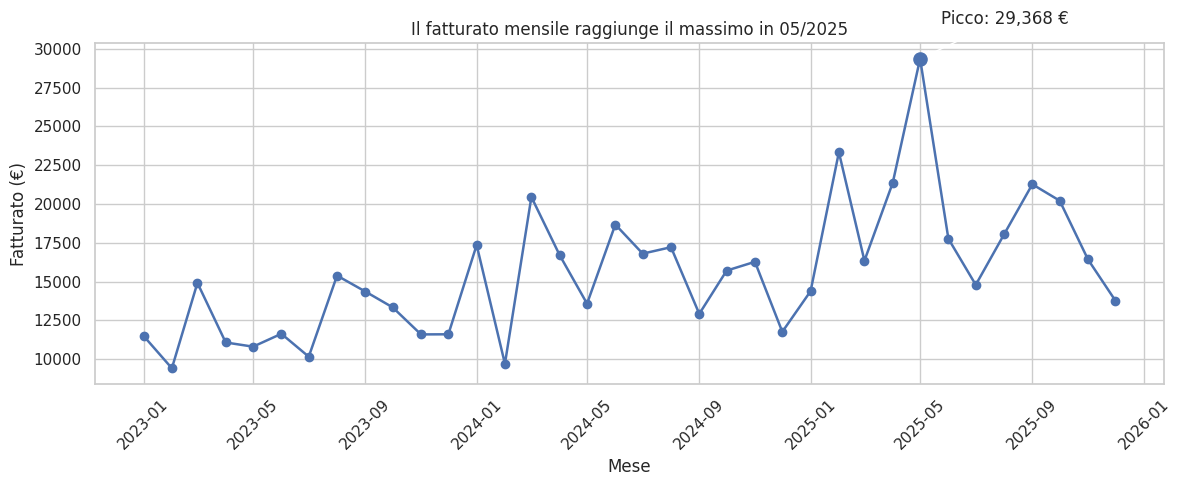

In [17]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(mensile["DataMese"], mensile["FatturatoMensile"], marker="o", linewidth=1.8)
ax.scatter([picco["DataMese"]], [picco["FatturatoMensile"]], zorder=5, s=90)
ax.annotate(f"Picco: {picco['FatturatoMensile']:,.0f} €",
            xy=(picco["DataMese"], picco["FatturatoMensile"]),
            xytext=(15, 25), textcoords="offset points",
            arrowprops={"arrowstyle": "->"})
ax.set_title(f"Il fatturato mensile raggiunge il massimo in {picco['DataMese']:%m/%Y}")
ax.set_xlabel("Mese")
ax.set_ylabel("Fatturato (€)")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

**Cosa mostra il grafico:** la linea permette di seguire l'andamento mese per mese. Il punto evidenziato indica il mese con il fatturato maggiore. Ci sono anche oscillazioni, quindi non basta guardare solo il valore massimo per dire che le vendite crescono sempre.


### Grafico 2 - Importi delle vendite per categoria

Confronto le categorie usando un boxplot, per vedere se alcune hanno vendite mediamente più alte o una maggiore variabilità.


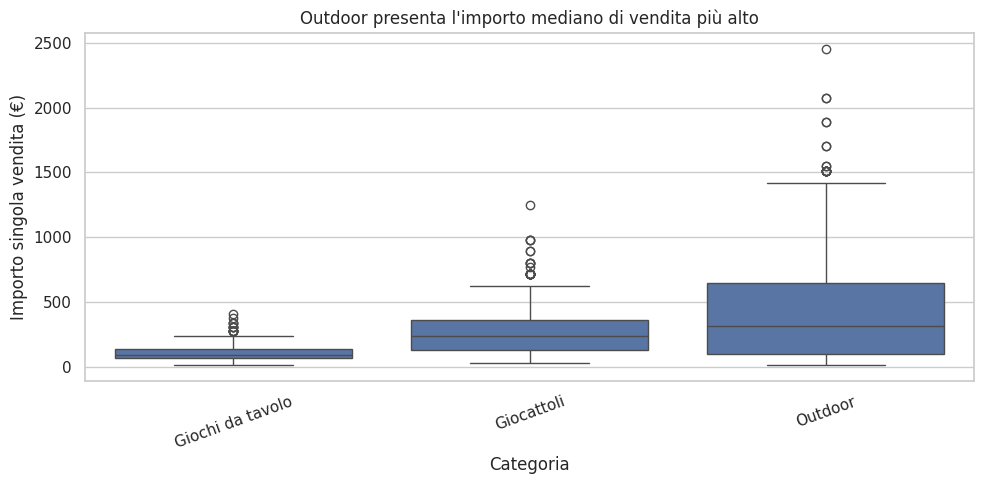

Mediane per categoria:


,Mediana
Category,
Outdoor,316.0
Giocattoli,236.0
Giochi da tavolo,89.5


In [18]:
mediane_cat = vendite_unite.groupby("Category")["SalesAmount"].median().sort_values(ascending=False)
cat_mediana_top = mediane_cat.index[0]
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=vendite_unite, x="Category", y="SalesAmount", ax=ax)
ax.set_title(f"{cat_mediana_top} presenta l'importo mediano di vendita più alto")
ax.set_xlabel("Categoria")
ax.set_ylabel("Importo singola vendita (€)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()
print("Mediane per categoria:")
display(mediane_cat.to_frame("Mediana"))

**Cosa mostra il grafico:** il boxplot fa vedere la mediana, la dispersione e i valori più lontani dagli altri. In questo modo posso confrontare le categorie senza fermarmi soltanto al fatturato totale. Le mediane stampate sotto aiutano a leggere il risultato.


### Grafico 3 - Correlazioni tra i dati dei rivenditori

Creo una heatmap per controllare quali caratteristiche dei rivenditori sembrano variare insieme, per esempio ordini, reclami e tempo trascorso dall'ultimo acquisto.


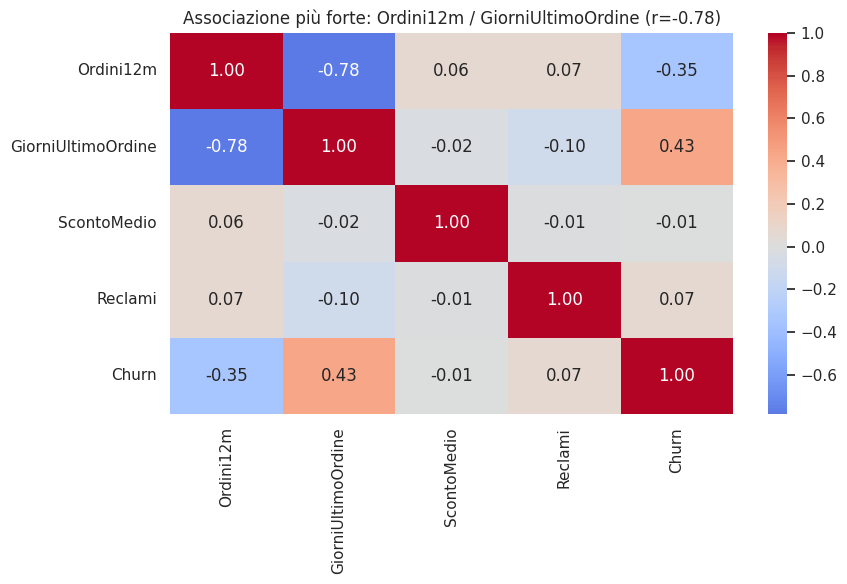

In [19]:
cols_corr = ["Ordini12m", "GiorniUltimoOrdine", "ScontoMedio", "Reclami", "Churn"]
matrice_corr = resellers[cols_corr].corr()
coppie_corr = matrice_corr.where(np.triu(np.ones(matrice_corr.shape), k=1).astype(bool)).stack()
coppia_max = coppie_corr.abs().idxmax()
valore_corr = matrice_corr.loc[coppia_max[0], coppia_max[1]]
fig, ax = plt.subplots(figsize=(9, 6))
sns.heatmap(matrice_corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title(f"Associazione più forte: {coppia_max[0]} / {coppia_max[1]} (r={valore_corr:.2f})")
plt.tight_layout()
plt.show()

**Cosa mostra il grafico:** i valori vicini a 1 indicano una correlazione positiva, quelli vicini a -1 una negativa e quelli vicini a 0 una relazione lineare debole. Non inserisco gli ID, perché sono codici identificativi e non quantità da confrontare. Una correlazione non significa automaticamente che una variabile causi l'altra.


### Grafico 4 - Fatturato per Stato (Plotly)

Aggiungo un grafico interattivo per confrontare gli Stati. Passando con il mouse sulle barre posso leggere anche la quantità venduta e il numero di transazioni.


In [20]:
import plotly.express as px

per_stato = (
    vendite_unite.groupby("State", as_index=False)
    .agg(Fatturato=("SalesAmount", "sum"),
         Quantita=("Quantity", "sum"),
         NumeroTransazioni=("SalesID", "count"))
    .sort_values("Fatturato", ascending=False)
)
stato_top = per_stato.iloc[0]["State"]
fig = px.bar(
    per_stato, x="State", y="Fatturato",
    hover_data={"Quantita": True, "NumeroTransazioni": True, "Fatturato": ":,.2f"},
    title=f"{stato_top} guida il fatturato complessivo per Stato",
    labels={"State": "Stato", "Fatturato": "Fatturato (€)"}
)
fig.show()
display(Markdown(
    f"**Domanda di business:** quale Stato contribuisce di più al fatturato? "
    f"**Risposta:** **{stato_top}** è al primo posto. Passando il mouse sulle barre si vedono "
    f"quantità e numero di transazioni, utili per distinguere importi elevati da volumi elevati."
))

**Domanda di business:** quale Stato contribuisce di più al fatturato? **Risposta:** **Austria** è al primo posto. Passando il mouse sulle barre si vedono quantità e numero di transazioni, utili per distinguere importi elevati da volumi elevati.

In sintesi, ho usato le **linee** per seguire le vendite nel tempo, le **barre** per confrontare i gruppi, il **boxplot** per vedere la distribuzione degli importi e la **heatmap** per le correlazioni.


---
## Task 5 - Previsione del fatturato

Qui provo a prevedere il fatturato usando la regressione lineare. Confronto due modelli: il primo usa soltanto il numero del mese, il secondo aggiunge anche quantità vendute e rivenditori attivi. Divido i dati in training e test per vedere come si comportano su mesi non usati per l'addestramento.


In [21]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

corr_mensile = mensile[["FatturatoMensile", "QuantitaMensile", "RivenditoriAttivi"]].corr()
print("Correlazioni richieste:")
display(corr_mensile)
triangolo = corr_mensile.where(np.triu(np.ones(corr_mensile.shape), k=1).astype(bool)).stack()
coppia_mensile = triangolo.abs().idxmax()
print(f"Coppia con correlazione in valore assoluto più forte: {coppia_mensile[0]} + {coppia_mensile[1]} (r={corr_mensile.loc[coppia_mensile]:.3f})")

Correlazioni richieste:


,FatturatoMensile,QuantitaMensile,RivenditoriAttivi
FatturatoMensile,1.000000,0.867742,0.556200
QuantitaMensile,0.867742,1.000000,0.673118
RivenditoriAttivi,0.556200,0.673118,1.000000


Coppia con correlazione in valore assoluto più forte: FatturatoMensile + QuantitaMensile (r=0.868)


In [22]:
X_semplice = mensile[["IndiceMese"]]
X_multiplo = mensile[["IndiceMese", "QuantitaMensile", "RivenditoriAttivi"]]
y_fatturato = mensile["FatturatoMensile"]

idx_train, idx_test = train_test_split(mensile.index, test_size=0.2, random_state=42)
modello_semplice = LinearRegression().fit(X_semplice.loc[idx_train], y_fatturato.loc[idx_train])
modello_multiplo = LinearRegression().fit(X_multiplo.loc[idx_train], y_fatturato.loc[idx_train])

risultati_regressione = []
for nome, modello, X_model in [
    ("Semplice", modello_semplice, X_semplice),
    ("Multipla", modello_multiplo, X_multiplo)
]:
    risultati_regressione.append({
        "Modello": nome,
        "Intercetta": modello.intercept_,
        "Coefficienti": dict(zip(X_model.columns, modello.coef_.round(3))),
        "R2 Train": r2_score(y_fatturato.loc[idx_train], modello.predict(X_model.loc[idx_train])),
        "R2 Test": r2_score(y_fatturato.loc[idx_test], modello.predict(X_model.loc[idx_test])),
    })
confronto_regressione = pd.DataFrame(risultati_regressione)
display(confronto_regressione)
print(f"Coefficiente del mese (modello semplice): {modello_semplice.coef_[0]:,.2f} € per mese")

,Modello,Intercetta,Coefficienti,R2 Train,R2 Test
0,Semplice,10906.106251,{'IndiceMese': 303.577},0.477107,-1.879054
1,Multipla,6245.567279,"{'IndiceMese': -78.105, 'QuantitaMensile': 85....",0.835974,-0.414757


Coefficiente del mese (modello semplice): 303.58 € per mese


### Come sono andati i due modelli?

Il modello semplice ha ottenuto **R² = 0,477 sul training** e **R² = -1,879 sul test**. Il modello con più variabili ha ottenuto **0,836 sul training** e **-0,415 sul test**.

Questo significa che sui dati di test **nessuno dei due modelli funziona bene**: un R² negativo indica un risultato peggiore rispetto a prevedere sempre la media. Il secondo si adatta meglio al training, ma non basta per avere previsioni affidabili.

Nel modello semplice il coefficiente del tempo è circa **+303,58 € al mese**. È il valore stimato dalla retta, **non** una crescita garantita delle vendite.


In [23]:
ultimo_mese = mensile["DataMese"].max()
previsione_mesi = pd.DataFrame({
    "DataMese": [ultimo_mese + pd.DateOffset(months=i) for i in range(1, 4)],
    "IndiceMese": list(range(len(mensile), len(mensile) + 3))
})
previsione_mesi["FatturatoPrevisto"] = modello_semplice.predict(previsione_mesi[["IndiceMese"]])
print("Tre previsioni indicative (modello semplice):")
display(previsione_mesi)
assert len(previsione_mesi) == 3

Tre previsioni indicative (modello semplice):


,DataMese,IndiceMese,FatturatoPrevisto
0,2026-01-01,36,21834.884948
1,2026-02-01,37,22138.462134
2,2026-03-01,38,22442.039321


### Cosa significano R² e correlazione?

**R²** mi dice quanto bene il modello riesce a spiegare i valori osservati rispetto a una previsione basata sulla media. Se vale 1 il risultato è perfetto, se vale 0 è paragonabile alla media, se è negativo è peggiore. Un **coefficiente di regressione** indica come cambia il valore previsto quando aumenta di un'unità una delle variabili, mantenendo ferme le altre nel modello multiplo. Anche una correlazione alta non dimostra un rapporto di causa-effetto. Inoltre prevedere mesi futuri è più incerto che descrivere quelli già osservati.


---
## Task 6a - Prevedere il churn dei rivenditori

Ora provo a individuare i rivenditori che potrebbero smettere di ordinare. Uso una regressione logistica con quattro informazioni: ordini negli ultimi 12 mesi, giorni dall'ultimo ordine, sconto medio e numero di reclami. Il valore da prevedere è `Churn`, che vale 1 quando il rivenditore è perso.


In [24]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             confusion_matrix, roc_auc_score)

features_churn = ["Ordini12m", "GiorniUltimoOrdine", "ScontoMedio", "Reclami"]
X_churn = resellers[features_churn]
y_churn = resellers["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X_churn, y_churn, test_size=0.2, random_state=42, stratify=y_churn
)
scaler_churn = StandardScaler()
X_train_scaled = scaler_churn.fit_transform(X_train)  # fit solo sui dati di train
X_test_scaled = scaler_churn.transform(X_test)        # transform sui dati di test

modello_churn = LogisticRegression(max_iter=1000, random_state=42)
modello_churn.fit(X_train_scaled, y_train)
prob_test = modello_churn.predict_proba(X_test_scaled)[:, 1]
pred_default = modello_churn.predict(X_test_scaled)   # soglia implicita 0.5
assert np.array_equal(pred_default, (prob_test >= 0.5).astype(int))
print("Train:", X_train.shape, "Test:", X_test.shape)
print("Distribuzione churn complessiva:")
display(y_churn.value_counts().rename("Numero").to_frame())

Train: (240, 4) Test: (60, 4)
Distribuzione churn complessiva:


,Numero
Churn,
0,229
1,71


In [25]:
def metriche_classificazione(y_vero, probabilita, soglia):
    predizioni = (probabilita >= soglia).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_vero, predizioni, labels=[0, 1]).ravel()
    return {
        "Soglia": soglia,
        "Accuracy": accuracy_score(y_vero, predizioni),
        "Precision": precision_score(y_vero, predizioni, zero_division=0),
        "Recall": recall_score(y_vero, predizioni, zero_division=0),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp
    }

tabella_metriche = pd.DataFrame([
    metriche_classificazione(y_test, prob_test, soglia=0.5),
    metriche_classificazione(y_test, prob_test, soglia=0.3)
])
print("Confronto delle due soglie (matrici di confusione TN, FP, FN, TP):")
display(tabella_metriche)

baseline_pred = np.zeros(len(y_test), dtype=int)
print(f"Accuracy baseline: {accuracy_score(y_test, baseline_pred):.3f} (predice sempre Churn=0)")
print(f"AUC Test (facoltativa): {roc_auc_score(y_test, prob_test):.3f}")

Confronto delle due soglie (matrici di confusione TN, FP, FN, TP):


,Soglia,Accuracy,Precision,Recall,TN,FP,FN,TP
0,0.5,0.766667,0.5,0.285714,42,4,10,4
1,0.3,0.766667,0.5,0.714286,36,10,4,10


Accuracy baseline: 0.767 (predice sempre Churn=0)
AUC Test (facoltativa): 0.761


In [26]:
# Confronto le matrici di confusione usando due soglie
for soglia in [0.5, 0.3]:
    y_pred_soglia = (prob_test >= soglia).astype(int)
    matrice = pd.DataFrame(
        confusion_matrix(y_test, y_pred_soglia, labels=[0, 1]),
        index=["Reale: non churn", "Reale: churn"],
        columns=["Predetto: non churn", "Predetto: churn"]
    )
    print(f"Matrice di confusione - soglia {soglia}:")
    display(matrice)

Matrice di confusione - soglia 0.5:


,Predetto: non churn,Predetto: churn
Reale: non churn,42,4
Reale: churn,10,4


Matrice di confusione - soglia 0.3:


,Predetto: non churn,Predetto: churn
Reale: non churn,36,10
Reale: churn,4,10


### Risultati della classificazione

Con la soglia **0,5** il modello ha **Accuracy 76,7%**, **Precision 50,0%** e **Recall 28,6%**: non trova 10 rivenditori che in realtà sono a rischio.

Abbassando la soglia a **0,3**, l'Accuracy resta **76,7%** e la Precision **50,0%**, mentre il Recall sale a **71,4%**. I rivenditori a rischio non riconosciuti scendono da 10 a **4**.

Un modello che risponde sempre “nessun churn” arriverebbe comunque al **76,7% di Accuracy**, ma non troverebbe nessun caso positivo. Per questo non considero soltanto l'Accuracy. Sul training e sul test, alla soglia 0,5, l'Accuracy è rispettivamente **77,5%** e **76,7%**: i valori sono simili, ma il Recall rimane basso.


In [27]:
prob_train = modello_churn.predict_proba(X_train_scaled)[:, 1]
diagnosi = pd.DataFrame([
    {"Campione": campione, "Accuracy": accuracy_score(y_vero, prob >= 0.5),
     "Recall": recall_score(y_vero, prob >= 0.5, zero_division=0)}
    for campione, y_vero, prob in [
        ("Train", y_train, prob_train),
        ("Test", y_test, prob_test)
    ]
])
display(diagnosi)
print("Differenza Accuracy train/test:", round(float(diagnosi.loc[0, "Accuracy"] - diagnosi.loc[1, "Accuracy"]), 3))

,Campione,Accuracy,Recall
0,Train,0.775000,0.315789
1,Test,0.766667,0.285714


Differenza Accuracy train/test: 0.008


### Quale soglia sceglierei?

In questo caso sceglierei di **valutare la soglia 0,3**, perché l'obiettivo è individuare più rivenditori che rischiamo di perdere. Un **falso negativo** è un rivenditore a rischio che il modello non segnala; un **falso positivo** è un rivenditore segnalato anche se non è a rischio. Abbassare la soglia può aumentare i falsi allarmi, quindi è importante confrontare tutte le metriche.

Se il modello va molto meglio sui dati di training che su quelli di test, può esserci **overfitting**. Se va male su entrambi, può esserci **underfitting**. Qui i due risultati di Accuracy sono simili, ma da soli non bastano a dire che il modello sia buono.

Questa classificazione è un esempio di **apprendimento supervisionato**, perché nel training conosco già il valore di `Churn`. Nel prossimo task, invece, userò un metodo non supervisionato per creare gruppi senza etichette già assegnate.


---
## Task 6b - Dividere i rivenditori in gruppi con K-Means

In questa parte raggruppo i rivenditori in base a ordini, tempo dall'ultimo ordine e fatturato. Prima calcolo il fatturato per ciascun rivenditore e preparo le variabili sulla stessa scala. In questo modo K-Means non viene influenzato troppo solo dalla variabile con i numeri più grandi.


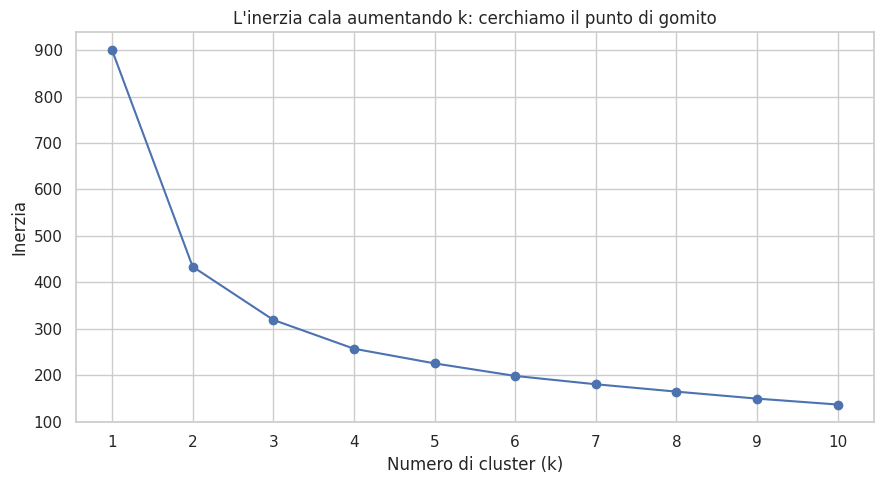

Inerzie per k:


,k,Inerzia
0,1,900.000000
1,2,433.727503
2,3,319.219233
3,4,257.174819
4,5,225.591174
5,6,198.576353
6,7,180.655458
7,8,164.768485
8,9,149.721017
9,10,137.028264


In [28]:
from sklearn.cluster import KMeans

fatturato_rivenditore = (
    vendite_unite.groupby("ResellerID")["SalesAmount"]
    .sum().rename("Fatturato")
)
resellers_cluster = resellers.merge(
    fatturato_rivenditore, left_on="ResellerID", right_index=True, how="left", validate="one_to_one"
)
resellers_cluster["Fatturato"] = resellers_cluster["Fatturato"].fillna(0)

features_cluster = ["Ordini12m", "GiorniUltimoOrdine", "Fatturato"]
scaler_cluster = StandardScaler()
X_cluster = scaler_cluster.fit_transform(resellers_cluster[features_cluster])

inerzie = []
for k in range(1, 11):
    modello_k = KMeans(n_clusters=k, n_init=10, random_state=42)
    modello_k.fit(X_cluster)
    inerzie.append(modello_k.inertia_)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(range(1, 11), inerzie, "o-")
ax.set_title("L'inerzia cala aumentando k: cerchiamo il punto di gomito")
ax.set_xlabel("Numero di cluster (k)")
ax.set_ylabel("Inerzia")
ax.set_xticks(range(1, 11))
plt.tight_layout()
plt.show()
print("Inerzie per k:")
display(pd.DataFrame({"k": range(1, 11), "Inerzia": inerzie}))

### Quanti gruppi creare?

Provo diversi valori di `k` e guardo il grafico del **metodo del gomito**. L'idea è vedere quando aggiungere altri gruppi porta un miglioramento sempre più piccolo. Qui uso **3 cluster**, così posso descrivere tre profili di rivenditori; è comunque una scelta da valutare osservando il grafico.


In [29]:
k_scelto = 3
kmeans = KMeans(n_clusters=k_scelto, n_init=10, random_state=42)
resellers_cluster["Cluster"] = kmeans.fit_predict(X_cluster)

profili_cluster = (
    resellers_cluster.groupby("Cluster")
    .agg(Rivenditori=("ResellerID", "count"),
         OrdiniMedi=("Ordini12m", "mean"),
         GiorniMediUltimoOrdine=("GiorniUltimoOrdine", "mean"),
         FatturatoMedio=("Fatturato", "mean"),
         QuotaChurn=("Churn", "mean"))
    .sort_values("FatturatoMedio", ascending=False)
)

# Nomi descrittivi derivati dall'ordine del fatturato medio e dai dati del gruppo.
nomi = ["Alto fatturato", "Medio fatturato", "Basso fatturato"]
nomi_cluster = {cluster: nomi[i] for i, cluster in enumerate(profili_cluster.index)}
resellers_cluster["NomeSegmento"] = resellers_cluster["Cluster"].map(nomi_cluster)
profili_cluster["NomeSegmento"] = profili_cluster.index.map(nomi_cluster)
profili_cluster["QuotaChurn%"] = (profili_cluster["QuotaChurn"] * 100).round(1)

display(profili_cluster[["NomeSegmento", "Rivenditori", "OrdiniMedi", "GiorniMediUltimoOrdine", "FatturatoMedio", "QuotaChurn%"]].round(2))
peggiore = profili_cluster["QuotaChurn"].idxmax()
segmento_critico = nomi_cluster[peggiore]
display(Markdown(
    f"**Segmento con churn più elevato:** **{segmento_critico} (cluster {peggiore})**, "
    f"con il **{profili_cluster.loc[peggiore, 'QuotaChurn%']:.1f}%** di churn. "
    f"Questo segmento merita maggiore attenzione nelle azioni di retention."
))

,NomeSegmento,Rivenditori,OrdiniMedi,GiorniMediUltimoOrdine,FatturatoMedio,QuotaChurn%
Cluster,,,,,,
2,Alto fatturato,68,21.66,45.90,3524.38,10.3
0,Medio fatturato,95,19.58,48.35,1514.70,10.5
1,Basso fatturato,137,12.42,141.48,1288.47,39.4


**Segmento con churn più elevato:** **Basso fatturato (cluster 1)**, con il **39.4%** di churn. Questo segmento merita maggiore attenzione nelle azioni di retention.

### Che cosa sono centroide e inerzia?

Il **centroide** è il punto centrale di un gruppo, calcolato sulle caratteristiche usate da K-Means. L'**inerzia** misura quanto i punti sono lontani dal centro del proprio gruppo: più è bassa, più i punti sono vicini ai centroidi. Però diminuisce anche aumentando il numero di gruppi, quindi non basta scegliere il valore più basso. In questo task non c'è una risposta corretta da prevedere: l'obiettivo è trovare gruppi con caratteristiche simili.


---
## Task 7 - Correzione degli errori e GitHub

Nell'ultimo task analizzo quattro esempi di codice che contengono errori o che possono essere scritti meglio. Lascio gli esempi sbagliati come testo, così non interrompono l'esecuzione del notebook. Subito sotto inserisco e provo la versione corretta.

**Richiesta usata per il supporto AI:** “Guarda questo codice Python, dimmi dove si trova l'errore, spiegamelo in modo semplice e mostrami come correggerlo cambiando soltanto ciò che serve. Indicami anche come controllare che funzioni.”


### Caso 1 - Calcolo della media

**Codice di partenza (sbagliato):**
```python
totale = 0
for v in sales["SalesAmount"]:
    totale += v
media = totale / len(sales)
```

**Problema:** nella colonna ci sono valori mancanti (`NaN`). Se li sommo così, anche il risultato può diventare `NaN`. Inoltre, per la media devo contare soltanto gli importi presenti.

**Soluzione:** uso `.mean()`, che esclude automaticamente i valori mancanti.


In [30]:
media_fatturato_corretta = sales["SalesAmount"].mean()
print(f"Caso 1 - media corretta: {media_fatturato_corretta:.2f} €")
assert np.isfinite(media_fatturato_corretta)

Caso 1 - media corretta: 294.78 €


### Caso 2 - Errore nella standardizzazione

**Codice di partenza (sbagliato):**
```python
scaler = StandardScaler()
X_s = scaler.fit_transform(X)
X_train, X_test, y_train, y_test = train_test_split(X_s, y)
```

**Problema:** facendo la standardizzazione prima di dividere il dataset, anche i dati di test influenzano il calcolo della media e della deviazione standard. Questo errore si chiama **data leakage**.

**Soluzione:** divido prima i dati. Poi uso `fit_transform` sul training e solo `transform` sul test.


In [31]:
X7_train, X7_test, y7_train, y7_test = train_test_split(
    resellers[features_churn], resellers["Churn"],
    test_size=0.2, random_state=42, stratify=resellers["Churn"]
)
scaler7 = StandardScaler()
X7_train_scaled = scaler7.fit_transform(X7_train)
X7_test_scaled = scaler7.transform(X7_test)
print("Caso 2 - split corretto:", X7_train_scaled.shape, X7_test_scaled.shape)

Caso 2 - split corretto: (240, 4) (60, 4)


### Caso 3 - Filtro delle vendite di biciclette

**Codice di partenza (sbagliato):**
```python
alte = df[(df["SalesAmount"] > 500) and
          (df["Category"] == "Bikes")]
print(alte.shape)
```

**Problema:** con Pandas, per unire due condizioni sulle colonne devo usare `&` e mettere ogni condizione tra parentesi. Inoltre, nel dataset non esiste una categoria chiamata `Bikes`: riconosco le biciclette dal nome del prodotto.

**Soluzione:** filtro gli importi oltre 500 € e i prodotti il cui nome contiene “Bici”.


In [32]:
alte_bici = vendite_unite.loc[
    (vendite_unite["SalesAmount"] > 500) &
    (vendite_unite["ProductName"].str.contains("Bici", case=False, na=False))
]
print("Caso 3 - vendite di biciclette sopra 500 €:", alte_bici.shape)
display(alte_bici[["SalesID", "ProductName", "SalesAmount"]].head())

Caso 3 - vendite di biciclette sopra 500 €: (250, 16)


,SalesID,ProductName,SalesAmount
17,1799,Bici BMX,567.0
28,1045,Bici BMX,1134.0
45,1872,Bici BMX,945.0
48,1639,Bici Junior,1161.0
53,207,Bici Junior,516.0


### Caso 4 - Rendere una funzione più chiara

**Codice di partenza:**
```python
def f(d, x):
    return d[d.iloc[:, 3] > x] \
        .iloc[:, 6].sum()
```

**Problema:** i nomi `f`, `d` e `x` non fanno capire cosa fa la funzione. Inoltre, selezionare le colonne tramite posizione è rischioso: se cambia l'ordine delle colonne, il risultato può essere sbagliato. In questi dati la quarta colonna è `ResellerID`, non `SalesAmount`.

**Soluzione:** uso nomi comprensibili e seleziono direttamente `SalesAmount` per trovare e sommare le vendite sopra la soglia.


In [33]:
def fatturato_vendite_sopra_soglia(df, soglia):
    """Somma il fatturato delle singole vendite di importo maggiore della soglia."""
    righe_selezionate = df.loc[df["SalesAmount"] > soglia]
    return righe_selezionate["SalesAmount"].sum()

risultato_caso4 = fatturato_vendite_sopra_soglia(vendite_unite, 500)
print(f"Caso 4 - fatturato delle vendite oltre 500 €: {risultato_caso4:,.2f} €")
assert risultato_caso4 >= 0

Caso 4 - fatturato delle vendite oltre 500 €: 292,075.70 €


### Cosa resta da fare per GitHub

- [x] Ho raccolto i task in un unico notebook.
- [x] Ho inserito gli esempi errati e le relative correzioni.
- [x] Nella cartella del progetto è presente anche il README.
- [ ] **Da completare:** creare il repository su GitHub, caricare i file e fare almeno **3 commit** con messaggi che spiegano i cambiamenti.

Per esempio, potrei usare questi messaggi: `Caricamento dei file e prime analisi`, `Pulizia dati e creazione dei grafici`, `Modelli ML e correzione degli errori`.

Prima della consegna devo anche eseguire tutte le celle dall'inizio alla fine in Colab e verificare che non ci siano errori.
